<a href="https://colab.research.google.com/github/igustingurahdwiandikaputra-code/StrukturData-Q1-2501010016-IGUSTINGURAHDWIANDIKA-KLS-A/blob/main/Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path


for d in ["data/raw", "data/interim", "notebooks", "docs", "reports"]:
    Path(d).mkdir(parents=True, exist_ok=True)

print("Folder siap:")
for d in sorted(Path(".").glob("*/*")):
    print(" ", d)

Folder siap:
  .config/.last_opt_in_prompt.yaml
  .config/.last_survey_prompt.yaml
  .config/.last_update_check.json
  .config/active_config
  .config/config_sentinel
  .config/configurations
  .config/default_configs.db
  .config/gce
  .config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
  .config/logs
  data/interim
  data/raw
  sample_data/README.md
  sample_data/anscombe.json
  sample_data/california_housing_test.csv
  sample_data/california_housing_train.csv
  sample_data/mnist_test.csv
  sample_data/mnist_train_small.csv


In [2]:
import json, time, hashlib
from datetime import datetime, timezone
from pathlib import Path
import pandas as pd
import requests
import matplotlib.pyplot as plt

NAMA  = "I Gusti Ngurah Dwi Andika Putra"
NIM   = "2501010016"
EMAIL = "igustingurahdwiandikaputra@instiki.ac.id"

URL = "https://overpass-api.de/api/interpreter"
HEADERS = {"User-Agent": f"INSTIKI-BIFP243-Praktikum/1.0 ({EMAIL})"}

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR     = ROOT / "data/raw"
INTERIM_DIR = ROOT / "data/interim"
DOCS_DIR    = ROOT / "docs"
REPORTS_DIR = ROOT / "reports"
for d in (RAW_DIR, INTERIM_DIR, DOCS_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [3]:
QUERY = """[out:json][timeout:90];
area["name"="Kintamani"]["boundary"="administrative"]["admin_level"="6"]->.kec;
nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"](area.kec);
out center tags;"""

(DOCS_DIR / "query_overpass.txt").write_text(QUERY, encoding="utf-8")
print(QUERY)

[out:json][timeout:90];
area["name"="Kintamani"]["boundary"="administrative"]["admin_level"="6"]->.kec;
nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"](area.kec);
out center tags;


In [4]:
def ambil_overpass(query, maks_percobaan=4, jeda=5):
    """POST query ke Overpass. Retry untuk 429/504 dan error jaringan, jeda dilipatduakan."""
    for percobaan in range(1, maks_percobaan + 1):
        try:
            r = requests.post(URL, data={"data": query}, headers=HEADERS, timeout=120)
            if r.status_code == 200:
                return r.json()
            print(f"[percobaan {percobaan}] status {r.status_code}, tunggu {jeda}s")
        except (requests.Timeout, requests.ConnectionError) as e:
            print(f"[percobaan {percobaan}] {type(e).__name__}, tunggu {jeda}s")
        time.sleep(jeda)
        jeda *= 2
    raise RuntimeError("Gagal mengambil data dari Overpass")

In [5]:
PAKSA_AMBIL_ULANG = False   # True hanya bila benar-benar perlu (jaga beban server dan IP kampus)

berkas_ada = sorted(RAW_DIR.glob("osm_akomodasi_kintamani_*.json"))

if berkas_ada and not PAKSA_AMBIL_ULANG:
    raw_path = berkas_ada[-1]
    print("Memakai berkas mentah yang sudah ada:", raw_path.name)
    data = json.loads(raw_path.read_text(encoding="utf-8"))
    waktu_akuisisi = datetime.fromtimestamp(raw_path.stat().st_mtime, tz=timezone.utc)
else:
    data = ambil_overpass(QUERY)
    waktu_akuisisi = datetime.now(timezone.utc)
    stamp = waktu_akuisisi.strftime("%Y%m%d_%H%M%S")
    raw_path = RAW_DIR / f"osm_akomodasi_kintamani_{stamp}.json"
    raw_path.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")
    print("Respons mentah disimpan:", raw_path.name)

print("Jumlah elemen:", len(data["elements"]))

Respons mentah disimpan: osm_akomodasi_kintamani_20261112_014713.json
Jumlah elemen: 32


In [6]:
md5 = hashlib.md5(raw_path.read_bytes()).hexdigest()

provenance = {
    "endpoint": URL,
    "query": QUERY,
    "waktu_akuisisi_utc": waktu_akuisisi.strftime("%Y-%m-%dT%H:%M:%SZ"),
    "jumlah_elemen": len(data["elements"]),
    "berkas_mentah": raw_path.name,
    "md5_berkas_mentah": md5,
    "lisensi": "ODbL 1.0 - © OpenStreetMap contributors",
    "pengambil": {"nama": NAMA, "nim": NIM},
}
(DOCS_DIR / "provenance.json").write_text(json.dumps(provenance, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(provenance, ensure_ascii=False, indent=2))

{
  "endpoint": "https://overpass-api.de/api/interpreter",
  "query": "[out:json][timeout:90];\narea[\"name\"=\"Kintamani\"][\"boundary\"=\"administrative\"][\"admin_level\"=\"6\"]->.kec;\nnwr[\"tourism\"~\"^(hotel|guest_house|hostel|motel|apartment|chalet)$\"](area.kec);\nout center tags;",
  "waktu_akuisisi_utc": "2026-11-12T01:47:13Z",
  "jumlah_elemen": 32,
  "berkas_mentah": "osm_akomodasi_kintamani_20261112_014713.json",
  "md5_berkas_mentah": "90271020529af180197745d4375ed4b5",
  "lisensi": "ODbL 1.0 - © OpenStreetMap contributors",
  "pengambil": {
    "nama": "I Gusti Ngurah Dwi Andika Putra",
    "nim": "2501010016"
  }
}


In [7]:
def ratakan(elements):
    baris = []
    for e in elements:
        tg = e.get("tags", {})
        pusat = e.get("center", e)  # node: lat/lon langsung; way/relation: di center
        baris.append({
            "osm_type": e["type"], "osm_id": e["id"],
            "nama": tg.get("name"), "jenis": tg.get("tourism"),
            "lat": pusat.get("lat"), "lon": pusat.get("lon"),
            "desa": tg.get("addr:village"),
            "bintang": tg.get("stars"), "jumlah_kamar": tg.get("rooms"),
            "website": tg.get("website") or tg.get("contact:website"),
            "url_osm": f"https://www.openstreetmap.org/{e['type']}/{e['id']}",
        })
    return pd.DataFrame(baris)

akomodasi = ratakan(data["elements"])
print("Bentuk tabel:", akomodasi.shape)
print("\nJumlah per jenis:")
print(akomodasi["jenis"].value_counts())
print("\nTanpa nama:", akomodasi["nama"].isna().sum())

assert len(akomodasi) == len(data["elements"]), "Ada elemen yang hilang saat perataan!"
kolom_terlarang = {"phone", "contact:phone", "email", "contact:email", "facebook", "instagram"}
assert not (kolom_terlarang & set(akomodasi.columns)), "Ada kolom kontak pribadi!"
print("OK: jumlah baris = jumlah elemen mentah, dan tidak ada kolom kontak pribadi")
akomodasi.head(10)

Bentuk tabel: (32, 11)

Jumlah per jenis:
jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64

Tanpa nama: 1
OK: jumlah baris = jumlah elemen mentah, dan tidak ada kolom kontak pribadi


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,None,None,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,None,None,None,None,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,None,None,None,None,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,None,None,None,None,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,None,2,5,None,https://www.openstreetmap.org/node/4297310696
5,node,4401927990,batur montáin view,hotel,-8.260754,115.338771,None,None,None,None,https://www.openstreetmap.org/node/4401927990
6,node,4863479822,Miranda Homestay & Restaurant,guest_house,-8.246313,115.327402,None,None,None,None,https://www.openstreetmap.org/node/4863479822
7,node,4905949623,Lava Stone Hostel,hostel,-8.250325,115.397136,None,None,None,None,https://www.openstreetmap.org/node/4905949623
8,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,None,None,None,None,https://www.openstreetmap.org/node/5065920543
9,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,None,None,None,None,https://www.openstreetmap.org/node/5175562421


In [8]:
keputusan = []

# 4a. Duplikat berdasarkan osm_type + osm_id
dup = akomodasi.duplicated(["osm_type", "osm_id"], keep="first")
print("Duplikat:", int(dup.sum()))
keputusan.append({"pemeriksaan": "duplikat osm_type+osm_id", "jumlah": int(dup.sum()),
                  "keputusan": "baris duplikat (kemunculan ke-2 dst.) dibuang" if dup.sum() else "tidak ada tindakan"})
akomodasi = akomodasi[~dup].reset_index(drop=True)

# 4b. Nama kosong (tetap disimpan, jumlahnya dilaporkan)
tanpa_nama = akomodasi["nama"].isna() | (akomodasi["nama"].astype(str).str.strip() == "")
print("Tanpa nama:", int(tanpa_nama.sum()))
keputusan.append({"pemeriksaan": "nama kosong", "jumlah": int(tanpa_nama.sum()),
                  "keputusan": "dipertahankan dan dihitung (sesuai ketentuan tugas)"})

# 4c. Koordinat kosong atau di luar kotak perkiraan Kintamani (SESUAIKAN dengan peta Anda)
LAT_MIN, LAT_MAX = -8.40, -8.05
LON_MIN, LON_MAX = 115.25, 115.55
koord_kosong = akomodasi["lat"].isna() | akomodasi["lon"].isna()
di_luar = ~koord_kosong & ~(akomodasi["lat"].between(LAT_MIN, LAT_MAX) & akomodasi["lon"].between(LON_MIN, LON_MAX))
print("Koordinat kosong:", int(koord_kosong.sum()), "| di luar kotak:", int(di_luar.sum()))
keputusan.append({"pemeriksaan": "koordinat kosong", "jumlah": int(koord_kosong.sum()),
                  "keputusan": "ditandai di baris_bermasalah.csv; periksa manual"})
keputusan.append({"pemeriksaan": f"koordinat di luar kotak lat[{LAT_MIN},{LAT_MAX}] lon[{LON_MIN},{LON_MAX}]",
                  "jumlah": int(di_luar.sum()), "keputusan": "ditandai di baris_bermasalah.csv; periksa manual, tidak dibuang"})

# 4d. Kolom yang hampir selalu kosong
kosong_persen = (akomodasi.isna().mean() * 100).round(1)
print("\nPersentase kosong per kolom:\n", kosong_persen)
for kol, p in kosong_persen.items():
    if p >= 80:
        keputusan.append({"pemeriksaan": f"kolom {kol} kosong {p}%", "jumlah": int(akomodasi[kol].isna().sum()),
                          "keputusan": "kolom dipertahankan sesuai struktur dataset; keterbatasan dicatat di laporan"})

akomodasi[tanpa_nama | koord_kosong | di_luar].to_csv(DOCS_DIR / "baris_bermasalah.csv", index=False, encoding="utf-8")
pd.DataFrame(keputusan).to_csv(DOCS_DIR / "keputusan_kualitas.csv", index=False, encoding="utf-8")
pd.DataFrame(keputusan)

Duplikat: 0
Tanpa nama: 1
Koordinat kosong: 0 | di luar kotak: 0

Persentase kosong per kolom:
 osm_type          0.0
osm_id            0.0
nama              3.1
jenis             0.0
lat               0.0
lon               0.0
desa            100.0
bintang          96.9
jumlah_kamar     93.8
website          93.8
url_osm           0.0
dtype: float64


,pemeriksaan,jumlah,keputusan
0,duplikat osm_type+osm_id,0,tidak ada tindakan
1,nama kosong,1,dipertahankan dan dihitung (sesuai ketentuan t...
2,koordinat kosong,0,ditandai di baris_bermasalah.csv; periksa manual
3,"koordinat di luar kotak lat[-8.4,-8.05] lon[11...",0,ditandai di baris_bermasalah.csv; periksa manu...
4,kolom desa kosong 100.0%,32,kolom dipertahankan sesuai struktur dataset; k...
5,kolom bintang kosong 96.9%,31,kolom dipertahankan sesuai struktur dataset; k...
6,kolom jumlah_kamar kosong 93.8%,30,kolom dipertahankan sesuai struktur dataset; k...
7,kolom website kosong 93.8%,30,kolom dipertahankan sesuai struktur dataset; k...


In [9]:
KOLOM = ["osm_type", "osm_id", "nama", "jenis", "lat", "lon", "desa", "bintang", "jumlah_kamar", "website", "url_osm"]
akomodasi[KOLOM].to_csv(INTERIM_DIR / "akomodasi_kintamani.csv", index=False, encoding="utf-8")
print("Disimpan:", INTERIM_DIR / "akomodasi_kintamani.csv", "-", len(akomodasi), "baris")

print("\nJumlah per jenis:")
print(akomodasi["jenis"].value_counts())
print("\nJumlah per desa:")
print(akomodasi["desa"].fillna("(tanpa tag desa)").value_counts())

Disimpan: /content/data/interim/akomodasi_kintamani.csv - 32 baris

Jumlah per jenis:
jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64

Jumlah per desa:
desa
(tanpa tag desa)    32
Name: count, dtype: int64


In [10]:
BPS_JUMLAH = None      # contoh: 120
TAHUN_BPS  = None      # contoh: 2024
SUMBER_BPS = "<tulis judul publikasi / portal dan halaman>"

n_osm = len(akomodasi)
if BPS_JUMLAH:
    kelengkapan = round(n_osm / BPS_JUMLAH * 100, 1)
    print(f"OSM: {n_osm} | BPS ({TAHUN_BPS}): {BPS_JUMLAH} | kelengkapan: {kelengkapan}%")
else:
    kelengkapan = None
    print(f"OSM: {n_osm}. Angka BPS belum diisi; isi BPS_JUMLAH atau jelaskan di laporan bila tidak ditemukan.")

perbandingan = pd.DataFrame([
    {"sumber": "OSM (hasil akuisisi)", "tahun": waktu_akuisisi.year, "jumlah_akomodasi": n_osm, "keterangan": raw_path.name},
    {"sumber": "BPS", "tahun": TAHUN_BPS, "jumlah_akomodasi": BPS_JUMLAH, "keterangan": SUMBER_BPS},
    {"sumber": "kelengkapan_persen", "tahun": None, "jumlah_akomodasi": kelengkapan, "keterangan": "OSM / BPS x 100"},
])
perbandingan.to_csv(DOCS_DIR / "perbandingan_bps.csv", index=False, encoding="utf-8")
perbandingan

OSM: 32. Angka BPS belum diisi; isi BPS_JUMLAH atau jelaskan di laporan bila tidak ditemukan.


,sumber,tahun,jumlah_akomodasi,keterangan
0,OSM (hasil akuisisi),2026.0,32.0,osm_akomodasi_kintamani_20261112_014713.json
1,BPS,NaN,NaN,<tulis judul publikasi / portal dan halaman>
2,kelengkapan_persen,NaN,NaN,OSM / BPS x 100


In [11]:
# 10 sampel acak (seed tetap agar bisa diulang). Verifikasi manual lewat url_osm dan/atau situs resmi akomodasi.
sampel = akomodasi.sample(n=min(10, len(akomodasi)), random_state=243)[
    ["osm_type", "osm_id", "nama", "jenis", "lat", "lon", "url_osm", "website"]].copy()
for kol in ["nama_benar", "jenis_benar", "lokasi_benar", "catatan"]:
    sampel[kol] = ""
sampel.to_csv(DOCS_DIR / "sampel_verifikasi.csv", index=False, encoding="utf-8")
print("Isi kolom nama_benar / jenis_benar / lokasi_benar (ya/tidak) dan catatan di docs/sampel_verifikasi.csv")
sampel

Isi kolom nama_benar / jenis_benar / lokasi_benar (ya/tidak) dan catatan di docs/sampel_verifikasi.csv


,osm_type,osm_id,nama,jenis,lat,lon,url_osm,website,nama_benar,jenis_benar,lokasi_benar,catatan
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,https://www.openstreetmap.org/node/1977779907,http://lakeviewbali.com/en/,,,,
30,node,13284479326,Lava Bali and Hot Spring,hotel,-8.250311,115.396374,https://www.openstreetmap.org/node/13284479326,None,,,,
21,node,7238422213,Batur Panorama,hotel,-8.218943,115.392130,https://www.openstreetmap.org/node/7238422213,None,,,,
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,https://www.openstreetmap.org/node/4150326329,None,,,,
19,node,7205318685,Tegal Suci Guest House,guest_house,-8.221410,115.412926,https://www.openstreetmap.org/node/7205318685,None,,,,
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,https://www.openstreetmap.org/node/4297310696,None,,,,
14,node,5668936157,Black Lava Hostel,hostel,-8.246333,115.396276,https://www.openstreetmap.org/node/5668936157,None,,,,
17,node,7058054537,Segara Hotel,hotel,-8.278086,115.379134,https://www.openstreetmap.org/node/7058054537,None,,,,
10,node,5181842726,Batur Volcano Guesthouse,guest_house,-8.249566,115.393837,https://www.openstreetmap.org/node/5181842726,None,,,,
15,node,6451134585,Caldera,hotel,-8.279139,115.367364,https://www.openstreetmap.org/node/6451134585,None,,,,


In [12]:
data_dictionary = pd.DataFrame([
    ["osm_type", "teks", "Jenis objek OSM: node, way, atau relation", "way", "Tidak"],
    ["osm_id", "bilangan bulat", "ID objek di OpenStreetMap", "123456789", "Tidak"],
    ["nama", "teks", "Nama akomodasi sesuai tag name", "(nama akomodasi)", "Ya, wajib dihitung jumlahnya"],
    ["jenis", "teks", "Nilai tag tourism", "guest_house", "Tidak"],
    ["lat", "desimal", "Koordinat lintang titik atau titik tengah bangunan (WGS84)", "-8.27", "Tidak"],
    ["lon", "desimal", "Koordinat bujur titik atau titik tengah bangunan (WGS84)", "115.37", "Tidak"],
    ["desa", "teks", "Desa sesuai tag addr:village", "(nama desa)", "Ya"],
    ["bintang", "teks", "Klasifikasi bintang (tag stars); teks karena isian relawan tidak selalu angka", "3", "Ya"],
    ["jumlah_kamar", "teks", "Jumlah kamar (tag rooms); teks karena isian relawan tidak selalu angka", "20", "Ya"],
    ["website", "teks", "Situs resmi akomodasi (tag website atau contact:website)", "https://…", "Ya"],
    ["url_osm", "teks", "Tautan ke objek di openstreetmap.org untuk pengecekan", "https://www.openstreetmap.org/way/…", "Tidak"],
], columns=["Kolom", "Tipe", "Deskripsi", "Contoh", "Boleh kosong?"])
data_dictionary.to_csv(DOCS_DIR / "data_dictionary.csv", index=False, encoding="utf-8")

# Konsistensi: kolom di data dictionary harus sama dengan kolom di CSV
csv_final = pd.read_csv(INTERIM_DIR / "akomodasi_kintamani.csv")
assert list(csv_final.columns) == list(data_dictionary["Kolom"]), "Data dictionary tidak cocok dengan CSV!"
print("OK: data dictionary konsisten dengan akomodasi_kintamani.csv")
data_dictionary

OK: data dictionary konsisten dengan akomodasi_kintamani.csv


,Kolom,Tipe,Deskripsi,Contoh,Boleh kosong?
0,osm_type,teks,"Jenis objek OSM: node, way, atau relation",way,Tidak
1,osm_id,bilangan bulat,ID objek di OpenStreetMap,123456789,Tidak
2,nama,teks,Nama akomodasi sesuai tag name,(nama akomodasi),"Ya, wajib dihitung jumlahnya"
3,jenis,teks,Nilai tag tourism,guest_house,Tidak
4,lat,desimal,Koordinat lintang titik atau titik tengah bang...,-8.27,Tidak
5,lon,desimal,Koordinat bujur titik atau titik tengah bangun...,115.37,Tidak
6,desa,teks,Desa sesuai tag addr:village,(nama desa),Ya
7,bintang,teks,Klasifikasi bintang (tag stars); teks karena i...,3,Ya
8,jumlah_kamar,teks,Jumlah kamar (tag rooms); teks karena isian re...,20,Ya
9,website,teks,Situs resmi akomodasi (tag website atau contac...,https://…,Ya


In [13]:
# Item otomatis diperiksa oleh kode. Item manual: ubah ke True HANYA setelah benar-benar Anda lakukan.
KONFIRMASI_MANUAL = {
    "hanya_sumber_diizinkan": False,   # hanya OSM Overpass (+ BPS/Satu Data Bali sebagai pembanding)
    "tanpa_scraping_ota":     False,   # tidak men-scrape OTA/platform pemesanan/Google Maps
    "query_seperlunya":       False,   # query dijalankan 1-2 kali saja
    "kendala_dilaporkan":     False,   # kendala server (bila ada) sudah ditulis di laporan
    "keterbatasan_dilaporkan":False,   # keterbatasan kelengkapan OSM ditulis di laporan dan refleksi
}

readme_path = ROOT / "README.md"
if not readme_path.exists():
    # Buat file README.md minimal agar pengecekan tidak error
    readme_path.write_text("# Proyek Analisis Akomodasi Kintamani\n\nAtribusi: Data di dalam proyek ini menggunakan data dari © OpenStreetMap contributors sesuai dengan Open Database License (ODbL). Tanggal akses: <ISI SETELAH AKUISISI; lihat docs/provenance.json>.", encoding="utf-8")

readme_teks = readme_path.read_text(encoding="utf-8")
prov = json.loads((DOCS_DIR / "provenance.json").read_text(encoding="utf-8"))
kunci_prov = {"endpoint", "query", "waktu_akuisisi_utc", "jumlah_elemen", "berkas_mentah", "md5_berkas_mentah", "lisensi", "pengambil"}
md5_cocok = hashlib.md5(raw_path.read_bytes()).hexdigest() == prov.get("md5_berkas_mentah")

def status(ok): return "Ya" if ok else "Belum"

checklist = pd.DataFrame([
    [1,  "Hanya memakai sumber yang diizinkan (OSM Overpass; BPS/Satu Data Bali untuk pembanding)", status(KONFIRMASI_MANUAL["hanya_sumber_diizinkan"]), "Konfirmasi manual; daftar sumber di README dan provenance.json"],
    [2,  "Tidak men-scrape OTA/platform pemesanan maupun Google Maps", status(KONFIRMASI_MANUAL["tanpa_scraping_ota"]), "Konfirmasi manual; satu-satunya endpoint di kode adalah " + URL],
    [3,  "Atribusi '© OpenStreetMap contributors' dicantumkan (ODbL)", status("© OpenStreetMap contributors" in readme_teks), "Dicek otomatis di README.md; tambahkan juga di laporan PDF"],
    [4,  "Tidak mengambil data kontak (telepon, email, media sosial)", status(not (kolom_terlarang & set(csv_final.columns))), "Dicek otomatis: tidak ada kolom kontak di akomodasi_kintamani.csv"],
    [5,  "Minimisasi data: hanya kolom yang diperlukan disimpan", status(list(csv_final.columns) == list(data_dictionary["Kolom"])), "Dicek otomatis: kolom CSV = data_dictionary.csv"],
    [6,  "Memakai User-Agent yang jelas dengan identitas pengambil", status(EMAIL in HEADERS["User-Agent"]), "Dicek otomatis: " + HEADERS["User-Agent"]],
    [7,  "Query dijalankan seperlunya (1-2 kali) dengan retry dan jeda", status(KONFIRMASI_MANUAL["query_seperlunya"]), "Konfirmasi manual; notebook memakai ulang berkas mentah yang ada"],
    [8,  "Berkas data/raw tidak diubah setelah disimpan", status(md5_cocok), "Dicek otomatis: MD5 berkas = MD5 di provenance.json"],
    [9,  "Data tidak dihapus diam-diam; keputusan dicatat", status((DOCS_DIR / "keputusan_kualitas.csv").exists()), "Dicek otomatis: docs/keputusan_kualitas.csv"],
    [10, "Provenance lengkap", status(kunci_prov <= set(prov)), "Dicek otomatis: docs/provenance.json memuat semua kunci wajib"],
    [11, "Keterbatasan kelengkapan OSM dinyatakan jujur", status(KONFIRMASI_MANUAL["keterbatasan_dilaporkan"]), "Konfirmasi manual; bagian 3 dan refleksi laporan"],
    [12, "Kendala server Overpass (bila ada) dilaporkan", status(KONFIRMASI_MANUAL["kendala_dilaporkan"]), "Konfirmasi manual; bagian 4 laporan"],
], columns=["No", "Item", "Status", "Bukti"])
checklist.to_csv(DOCS_DIR / "data_ethics_checklist.csv", index=False, encoding="utf-8")
print((checklist["Status"] == "Ya").sum(), "dari", len(checklist), "item berstatus Ya")
checklist

7 dari 12 item berstatus Ya


,No,Item,Status,Bukti
0,1,Hanya memakai sumber yang diizinkan (OSM Overp...,Belum,Konfirmasi manual; daftar sumber di README dan...
1,2,Tidak men-scrape OTA/platform pemesanan maupun...,Belum,Konfirmasi manual; satu-satunya endpoint di ko...
2,3,Atribusi '© OpenStreetMap contributors' dicant...,Ya,Dicek otomatis di README.md; tambahkan juga di...
3,4,"Tidak mengambil data kontak (telepon, email, m...",Ya,Dicek otomatis: tidak ada kolom kontak di akom...
4,5,Minimisasi data: hanya kolom yang diperlukan d...,Ya,Dicek otomatis: kolom CSV = data_dictionary.csv
5,6,Memakai User-Agent yang jelas dengan identitas...,Ya,Dicek otomatis: INSTIKI-BIFP243-Praktikum/1.0 ...
6,7,Query dijalankan seperlunya (1-2 kali) dengan ...,Belum,Konfirmasi manual; notebook memakai ulang berk...
7,8,Berkas data/raw tidak diubah setelah disimpan,Ya,Dicek otomatis: MD5 berkas = MD5 di provenance...
8,9,Data tidak dihapus diam-diam; keputusan dicatat,Ya,Dicek otomatis: docs/keputusan_kualitas.csv
9,10,Provenance lengkap,Ya,Dicek otomatis: docs/provenance.json memuat se...


In [14]:
# Lengkapi tanggal akses dan tahun BPS di README (aman dijalankan ulang)
readme_path = ROOT / "README.md"
teks = readme_path.read_text(encoding="utf-8")
teks = teks.replace("<ISI SETELAH AKUISISI; lihat docs/provenance.json>",
                    f"{waktu_akuisisi.strftime('%d %B %Y')} (UTC); rincian di docs/provenance.json")
if TAHUN_BPS:
    teks = teks.replace("<TAHUN>", str(TAHUN_BPS))
readme_path.write_text(teks, encoding="utf-8")

sisa = [p for p in ["<NAMA>", "<NIM>", "<TAHUN>", "<ISI SETELAH AKUISISI"] if p in teks]
print("Placeholder README yang masih perlu diisi manual:", sisa if sisa else "tidak ada")

Placeholder README yang masih perlu diisi manual: tidak ada


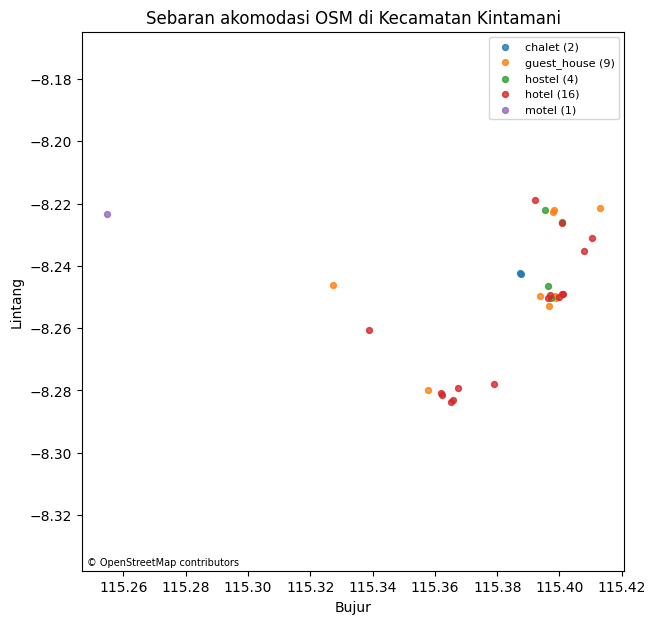

In [15]:
plot_df = akomodasi.dropna(subset=["lat", "lon"])
fig, ax = plt.subplots(figsize=(7, 7))
for jenis, grup in plot_df.groupby("jenis"):
    ax.scatter(grup["lon"], grup["lat"], s=18, label=f"{jenis} ({len(grup)})", alpha=0.8)
ax.set_xlabel("Bujur"); ax.set_ylabel("Lintang")
ax.set_title("Sebaran akomodasi OSM di Kecamatan Kintamani")
ax.legend(fontsize=8)
ax.text(0.01, 0.01, "© OpenStreetMap contributors", transform=ax.transAxes, fontsize=7)
ax.set_aspect("equal", adjustable="datalim")
fig.savefig(REPORTS_DIR / "peta_sebaran.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
ringkasan = pd.DataFrame({
    "per_jenis": akomodasi["jenis"].value_counts(),
}).fillna(0).astype(int)
print("Total akomodasi:", len(akomodasi))
print("\nPer jenis:\n", akomodasi["jenis"].value_counts())
print("\nPer desa:\n", akomodasi["desa"].fillna("(tanpa tag desa)").value_counts())

Total akomodasi: 32

Per jenis:
 jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64

Per desa:
 desa
(tanpa tag desa)    32
Name: count, dtype: int64
